# 13 — PVOD data exploration

## Purpose

We examine the ten-station **PVOD photovoltaic dataset** before constructing forecasting samples. The analysis establishes station characteristics, measurement cadence, timestamp quality, temporal gaps, nominal-capacity normalization, and the distinction between daylight and all-hours PV output.

This notebook follows the PVOD conventions already used in the cross-dataset forecasting experiment. The observations remain in their original station-specific time grids, and the source measurements are not interpolated or clipped. The next notebook will use these checks to document the full forecasting preparation protocol.

## 1. Load the station registry

The PVOD release contains `metadata.csv` and `station00.csv` through `station09.csv` under `external_data/PVOD/`. Metadata provides the latitude, longitude and nominal PV capacity of each station. Capacity is converted from kW to MW so that observed power in MW can be expressed as a proportion of nominal capacity.

The supplied station timestamps are interpreted as UTC under the existing PVOD protocol; `Asia/Shanghai` is used only for local-time interpretation and visualizations.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / "src" / "pvod.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run the notebook inside the SOLETE project repository.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.pvod import (
    PVOD_CADENCE,
    PVOD_METEOROLOGICAL_COLUMNS,
    PVOD_TIMESTAMP_CORRECTIONS,
    build_pvod_site_registry,
    build_pvod_solar_features,
    clean_pvod_station,
)

PVOD_ROOT = PROJECT_ROOT / "external_data" / "PVOD"
STATIONS = tuple(f"station{i:02d}" for i in range(10))
required_files = [PVOD_ROOT / "metadata.csv"] + [PVOD_ROOT / f"{s}.csv" for s in STATIONS]
missing_files = [str(p) for p in required_files if not p.is_file()]
if missing_files:
    raise FileNotFoundError("Missing PVOD release files: " + ", ".join(missing_files))
assert PVOD_CADENCE == pd.Timedelta(minutes=15)
assert set(PVOD_TIMESTAMP_CORRECTIONS) == {"station00"}

raw_metadata = pd.read_csv(PVOD_ROOT / "metadata.csv")
registry = build_pvod_site_registry(raw_metadata)
assert len(registry) == len(STATIONS)
assert set(registry["station"]) == set(STATIONS)
registry = registry.set_index("station").loc[list(STATIONS)].reset_index()
assert registry["capacity_MW"].gt(0).all()

print("PVOD stations:", len(registry))
print("Cadence:", PVOD_CADENCE)
print("Nominal capacities are metadata values, not estimated from measured output.")
display(registry[["station", "latitude_deg", "longitude_deg", "capacity_kW", "capacity_MW"]])

PVOD stations: 10
Cadence: 0 days 00:15:00
Nominal capacities are metadata values, not estimated from measured output.


,station,latitude_deg,longitude_deg,capacity_kW,capacity_MW
0,station00,38.047780,114.951390,6600,6.6
1,station01,38.183060,117.457220,20000,20.0
2,station02,38.057280,114.198870,17000,17.0
3,station03,38.109560,114.114940,20000,20.0
4,station04,39.515500,114.867670,20000,20.0
5,station05,38.235500,114.123600,35000,35.0
6,station06,36.898910,114.548410,15000,15.0
7,station07,36.644030,113.641870,20000,20.0
8,station08,36.707610,113.899990,20000,20.0
9,station09,38.731417,115.059855,20000,20.0


## 2. Inspect the measurement schema

Each station contains recorded PV power and thirteen meteorological channels, including numerical-weather-prediction and local measurement variables. The PV target is `power` in MW. We assess its basic quality together with the timestamps before applying the documented PVOD cleaning function.

Missingness is counted on the original CSV, so it remains distinguishable from temporal gaps between valid rows.

In [2]:
raw_schema_rows = []
required_data_columns = {"date_time", "power", *PVOD_METEOROLOGICAL_COLUMNS}
for station in STATIONS:
    raw = pd.read_csv(PVOD_ROOT / f"{station}.csv")
    assert required_data_columns.issubset(raw.columns), (
        station, sorted(required_data_columns - set(raw.columns))
    )
    raw_time = pd.to_datetime(raw["date_time"], errors="raise")
    assert raw_time.dt.tz is None, "The PVOD source timestamp convention changed."
    raw_schema_rows.append({
        "station": station,
        "raw_rows": len(raw),
        "raw_duplicate_timestamps": int(raw_time.duplicated().sum()),
        "raw_chronologically_ordered": bool(raw_time.is_monotonic_increasing),
        "missing_measurement_values": int(raw[["power", *PVOD_METEOROLOGICAL_COLUMNS]].isna().sum().sum()),
        "recorded_columns": len(raw.columns),
    })
raw_quality = pd.DataFrame(raw_schema_rows)
assert len(raw_quality) == 10 and raw_quality["raw_rows"].gt(0).all()
print("Original CSV schema and quality audit:")
display(raw_quality)

Original CSV schema and quality audit:


,station,raw_rows,raw_duplicate_timestamps,raw_chronologically_ordered,missing_measurement_values,recorded_columns
0,station00,28896,1,False,0,15
1,station01,33408,0,True,0,15
2,station02,30432,0,True,0,15
3,station03,14688,0,True,0,15
4,station04,33408,0,True,0,15
5,station05,9696,0,True,0,15
6,station06,31104,0,True,0,15
7,station07,32928,0,True,0,15
8,station08,33120,0,True,0,15
9,station09,24288,0,True,0,15


## 3. Apply the frozen timestamp and power conventions

The project’s `clean_pvod_station` function applies the established single-row timestamp correction in station00, sorts records chronologically and normalizes power by nominal capacity. It does **not** fill missing timestamps or clip recorded output above nominal capacity.

The station-level audit below measures missing 15-minute slots from the corrected timestamps, the longest observed gap and the fraction of observations outside the nominal 0–1 p.u. operating range. A value above 1 p.u. is retained as a measurement, rather than forcibly altered.

In [3]:
station_summary_rows = []
monthly_parts = []
example_frame = None

site_lookup = registry.set_index("station")
for station in STATIONS:
    site = site_lookup.loc[station]
    raw = pd.read_csv(PVOD_ROOT / f"{station}.csv")
    clean = clean_pvod_station(
        raw,
        station_id=station,
        capacity_kw=float(site["capacity_kW"]),
    )
    times = pd.DatetimeIndex(clean["timestamp_utc"])
    assert str(times.tz) == "UTC" and times.is_monotonic_increasing and times.is_unique
    assert len(clean) == int(raw_quality.set_index("station").loc[station, "raw_rows"])
    assert np.isfinite(clean["power_pu"].to_numpy()).all()
    assert np.allclose(
        clean["power_MW"].to_numpy() / float(site["capacity_MW"]),
        clean["power_pu"].to_numpy(),
        rtol=1e-12, atol=1e-12,
    )

    step_sizes = np.asarray((times[1:] - times[:-1]) / PVOD_CADENCE, dtype=float)
    assert (step_sizes >= 1).all()
    assert np.isclose(step_sizes, np.rint(step_sizes)).all(), "Non-grid gap detected."
    missing_slots = int((np.rint(step_sizes).astype(int) - 1).sum())
    gap_count = int((step_sizes > 1).sum())
    max_gap_minutes = float(step_sizes.max() * 15) if len(step_sizes) else 0.0

    solar = build_pvod_solar_features(
        times,
        latitude_deg=float(site["latitude_deg"]),
        longitude_deg=float(site["longitude_deg"]),
    )
    assert solar.shape == (len(clean), 5) and solar.index.equals(times)
    daylight = solar["solar_daylight"].to_numpy(dtype=bool)
    power = clean["power_pu"].to_numpy(dtype=float)

    station_summary_rows.append({
        "station": station,
        "latitude_deg": float(site["latitude_deg"]),
        "longitude_deg": float(site["longitude_deg"]),
        "capacity_MW": float(site["capacity_MW"]),
        "first_time_UTC": times.min(),
        "last_time_UTC": times.max(),
        "observed_rows": len(clean),
        "missing_15min_slots": missing_slots,
        "gaps_longer_than_15min": gap_count,
        "longest_timestamp_gap_min": max_gap_minutes,
        "daylight_rows": int(daylight.sum()),
        "night_rows": int((~daylight).sum()),
        "mean_power_pu": float(power.mean()),
        "daylight_mean_power_pu": float(power[daylight].mean()),
        "night_mean_power_pu": float(power[~daylight].mean()),
        "zero_power_rows": int((power == 0).sum()),
        "negative_power_rows": int((power < 0).sum()),
        "above_capacity_rows": int((power > 1).sum()),
        "max_power_pu": float(power.max()),
    })

    months = pd.DatetimeIndex(clean["timestamp_china"]).strftime("%Y-%m")
    monthly = pd.DataFrame({
        "month_china": months,
        "power_pu": power,
        "solar_daylight": daylight.astype(int),
    }).groupby("month_china", sort=True).agg(
        rows=("power_pu", "size"),
        daylight_rows=("solar_daylight", "sum"),
        mean_power_pu=("power_pu", "mean"),
    ).reset_index()
    daylight_months = pd.DataFrame({
        "month_china": months[daylight], "power_pu": power[daylight],
    }).groupby("month_china")["power_pu"].mean().rename("daylight_mean_power_pu")
    monthly = monthly.merge(daylight_months, on="month_china", how="left", validate="one_to_one")
    monthly.insert(0, "station", station)
    monthly_parts.append(monthly)

    if station == "station00":
        example_frame = clean[["timestamp_utc", "power_pu"]].copy()
        example_frame["solar_elevation_deg"] = solar["solar_elevation_deg"].to_numpy()

station_summary = pd.DataFrame(station_summary_rows)
monthly_summary = pd.concat(monthly_parts, ignore_index=True)
assert len(station_summary) == 10 and station_summary["station"].is_unique
assert station_summary["observed_rows"].sum() == raw_quality["raw_rows"].sum()
assert station_summary["negative_power_rows"].eq(0).all()
assert station_summary["night_rows"].gt(0).all()
assert station_summary["daylight_rows"].gt(0).all()

print("Corrected station timeline and nominal-capacity summary:")
display(station_summary.round(5))
print("Total observed rows:", int(station_summary["observed_rows"].sum()))
print("Total missing 15-minute slots across station time spans:", int(station_summary["missing_15min_slots"].sum()))

Corrected station timeline and nominal-capacity summary:


/var/folders/c2/r4zn6_kd1cx7xc1k98qrt5qw0000gn/T/ipykernel_80291/666084734.py:92: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(station_summary.round(5))


,station,latitude_deg,longitude_deg,capacity_MW,first_time_UTC,last_time_UTC,observed_rows,missing_15min_slots,gaps_longer_than_15min,longest_timestamp_gap_min,daylight_rows,night_rows,mean_power_pu,daylight_mean_power_pu,night_mean_power_pu,zero_power_rows,negative_power_rows,above_capacity_rows,max_power_pu
0,station00,38.04778,114.95139,6.6,2018-08-15 16:00:00+00:00,2019-06-13 15:45:00+00:00,28896,96,1,1455.0,13935,14961,0.12592,0.26111,0.00000,15717,0,0,0.83683
1,station01,38.18306,117.45722,20.0,2018-06-30 16:00:00+00:00,2019-06-13 15:45:00+00:00,33408,0,0,15.0,16596,16812,0.18388,0.36727,0.00284,17317,0,0,0.99987
2,station02,38.05728,114.19887,17.0,2018-07-22 16:00:00+00:00,2019-06-10 15:45:00+00:00,30432,576,3,4335.0,14855,15577,0.15185,0.31107,0.00000,16227,0,0,0.94401
3,station03,38.10956,114.11494,20.0,2019-01-11 16:00:00+00:00,2019-06-13 15:45:00+00:00,14688,0,0,15.0,7505,7183,0.16874,0.33025,0.00000,7694,0,0,0.87096
4,station04,39.51550,114.86767,20.0,2018-06-30 16:00:00+00:00,2019-06-13 15:45:00+00:00,33408,0,0,15.0,16572,16836,0.22671,0.45704,0.00000,17672,0,1578,1.33840
5,station05,38.23550,114.12360,35.0,2019-03-04 16:00:00+00:00,2019-06-13 15:45:00+00:00,9696,0,0,15.0,5350,4346,0.20159,0.36534,0.00001,4346,0,1,1.00338
6,station06,36.89891,114.54841,15.0,2018-07-13 16:00:00+00:00,2019-06-13 15:45:00+00:00,31104,1056,5,8655.0,15348,15756,0.11288,0.22876,0.00000,16034,0,0,0.78273
7,station07,36.64403,113.64187,20.0,2018-06-30 16:00:00+00:00,2019-06-13 15:45:00+00:00,32928,480,1,7215.0,16363,16565,0.13093,0.26347,0.00000,18018,0,0,0.86403
8,station08,36.70761,113.89999,20.0,2018-06-30 16:00:00+00:00,2019-06-13 15:45:00+00:00,33120,288,1,4335.0,16476,16644,0.14404,0.28955,0.00000,17162,0,0,0.89330
9,station09,38.73142,115.05986,20.0,2018-09-25 16:00:00+00:00,2019-06-13 15:45:00+00:00,24288,768,4,4335.0,11481,12807,0.06764,0.14310,0.00000,13287,0,0,0.60225


Total observed rows: 271968
Total missing 15-minute slots across station time spans: 3264


## 4. Visualize temporal gaps and PV output

Missing time slots differ from nighttime zeros: a missing slot contains no observation, whereas a nighttime row may legitimately record zero PV generation. The first figure reports missing grid slots by station. The second displays a short observation window from station00, with geometric solar elevation shown separately from normalized measured PV output.

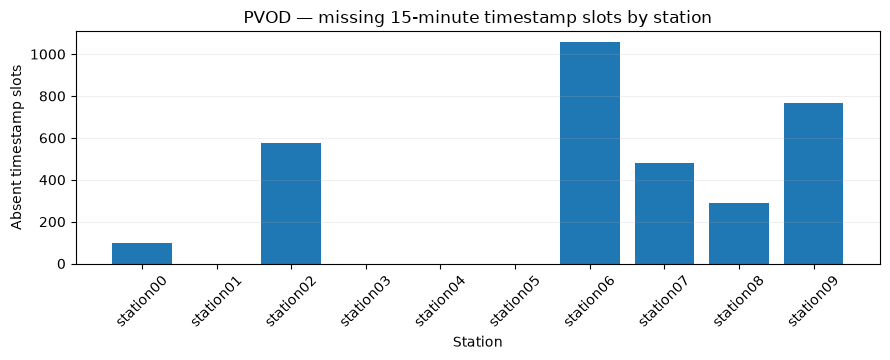

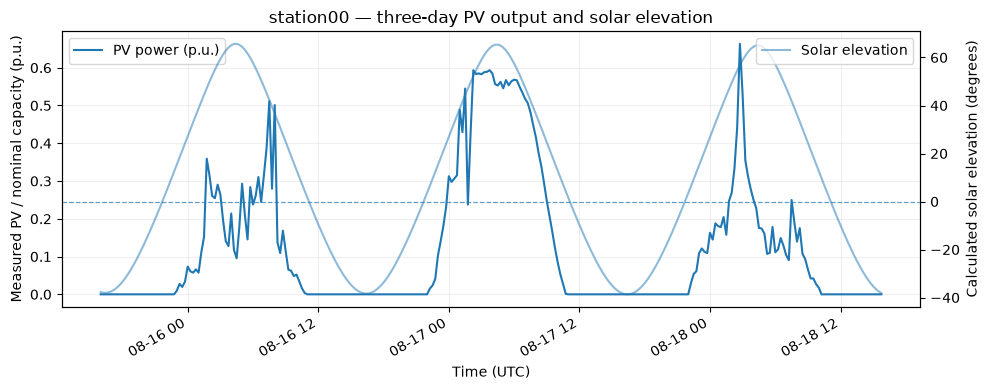

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.7))
ax.bar(station_summary["station"], station_summary["missing_15min_slots"])
ax.set_title("PVOD — missing 15-minute timestamp slots by station")
ax.set_xlabel("Station")
ax.set_ylabel("Absent timestamp slots")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

assert example_frame is not None
start = example_frame["timestamp_utc"].iloc[0]
window = example_frame.loc[example_frame["timestamp_utc"].lt(start + pd.Timedelta(days=3))]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(window["timestamp_utc"], window["power_pu"], label="PV power (p.u.)")
ax.set_ylabel("Measured PV / nominal capacity (p.u.)")
ax.set_xlabel("Time (UTC)")
ax.grid(alpha=0.2)
twin = ax.twinx()
twin.plot(window["timestamp_utc"], window["solar_elevation_deg"], alpha=0.5, label="Solar elevation")
twin.axhline(0, linestyle="--", linewidth=0.9, alpha=0.7)
twin.set_ylabel("Calculated solar elevation (degrees)")
ax.set_title("station00 — three-day PV output and solar elevation")
ax.legend(loc="upper left")
twin.legend(loc="upper right")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## 5. Daylight and all-hours populations

The solar experiment uses all eligible observations for model training, including nighttime. Forecasting performance is reported both over all hours and over target-valid times when **geometric solar elevation is positive**. This is the same daylight definition used by the existing PVOD evaluation.

Daylight results provide a clearer view of errors when the plant can generate electricity. They are a complementary interpretation of the already frozen all-hours training and selection procedure.

In [5]:
population_summary = station_summary[[
    "station", "observed_rows", "daylight_rows", "night_rows",
    "mean_power_pu", "daylight_mean_power_pu", "night_mean_power_pu",
]].copy()
population_summary["daylight_fraction_pct"] = (
    100 * population_summary["daylight_rows"] / population_summary["observed_rows"]
)
assert (population_summary["daylight_rows"] + population_summary["night_rows"]
        == population_summary["observed_rows"]).all()
print("Solar-power observation populations (before lag/target eligibility filters):")
display(population_summary.round(4))
print("PV output above nominal capacity is retained in the source-based forecasting protocol.")
print("These are raw timeline counts, not eligible forecasting-sample counts.")

Solar-power observation populations (before lag/target eligibility filters):


,station,observed_rows,daylight_rows,night_rows,mean_power_pu,daylight_mean_power_pu,night_mean_power_pu,daylight_fraction_pct
0,station00,28896,13935,14961,0.1259,0.2611,0.0000,48.2247
1,station01,33408,16596,16812,0.1839,0.3673,0.0028,49.6767
2,station02,30432,14855,15577,0.1518,0.3111,0.0000,48.8137
3,station03,14688,7505,7183,0.1687,0.3302,0.0000,51.0961
4,station04,33408,16572,16836,0.2267,0.4570,0.0000,49.6049
5,station05,9696,5350,4346,0.2016,0.3653,0.0000,55.1774
6,station06,31104,15348,15756,0.1129,0.2288,0.0000,49.3441
7,station07,32928,16363,16565,0.1309,0.2635,0.0000,49.6933
8,station08,33120,16476,16644,0.1440,0.2895,0.0000,49.7464
9,station09,24288,11481,12807,0.0676,0.1431,0.0000,47.2703


PV output above nominal capacity is retained in the source-based forecasting protocol.
These are raw timeline counts, not eligible forecasting-sample counts.


## 6. Save exploration tables

The station and monthly summaries preserve the data-quality observations used to explain the forecasting protocol. They contain aggregated measurements rather than copies of the source station data.

The next notebook will verify each station's cleaned F0 history, train/validation/test date boundaries and gap-safe 15-, 30- and 60-minute forecasting populations.

In [6]:
OUTPUT = PROJECT_ROOT / "results" / "pvod_methodology"
OUTPUT.mkdir(parents=True, exist_ok=True)
tables = {
    "pvod_raw_quality.csv": raw_quality,
    "pvod_station_exploration.csv": station_summary,
    "pvod_monthly_exploration.csv": monthly_summary,
}
for name, frame in tables.items():
    destination = OUTPUT / name
    frame.to_csv(destination, index=False, float_format="%.12g")
    assert len(pd.read_csv(destination)) == len(frame)
    print(destination.relative_to(PROJECT_ROOT))

assert set(station_summary["station"]) == set(STATIONS)
assert station_summary["first_time_UTC"].notna().all()
assert station_summary["last_time_UTC"].notna().all()
print("NOTEBOOK 15: PVOD DATA EXPLORATION CHECKS PASSED")

results/pvod_methodology/pvod_raw_quality.csv
results/pvod_methodology/pvod_station_exploration.csv
results/pvod_methodology/pvod_monthly_exploration.csv
NOTEBOOK 15: PVOD DATA EXPLORATION CHECKS PASSED


## Findings and interpretation

The tables above establish the station capacities and geographic coverage, document the corrected timestamp quality, quantify genuine missing 15-minute slots, and describe normalized PV output by solar daylight status. The plots show the observed time-grid gaps and the relationship between recorded power and computed solar elevation for an example station.

These findings are descriptive. The downstream station-specific forecasting protocol uses the same recorded timeline, power-normalization rule and daylight convention, without interpolating gaps or changing the PV measurements.